<a href="https://colab.research.google.com/github/ciscokn-sys/Flood-Risk-Classifier-Project-by-Kenneth-Egwueinu/blob/main/_Flood_Risk_Classifier_Project_by_Kenneth_Egwueinu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Flood Risk Classifier
Community Flood Risk Classification Using XGBoost

This project is designed to classify flood risk levels in river-line communities into:

Low Risk
Moderate Risk
High Risk

using environmental and socio-economic factors from the Flood Prediction Dataset.

1. Project Overview
Problem Statement

Flooding is one of the most destructive natural disasters affecting communities along rivers.

The aim of this project is to develop a Machine Learning model that predicts the flood risk level of a community based on environmental conditions such as:

Monsoon Intensity
Topography Drainage
River Management
Deforestation
Urbanization
Climate Change
Dams Quality
Coastal Vulnerability
Population Score

The model will help communities and local authorities improve flood awareness and preparedness.

2. Project Objectives
Main Objective

Build an intelligent Flood Risk Classifier that predicts:

Low
Moderate
High

flood risk categories.

Specific Objectives

 Data preprocessing

 Feature engineering

 Flood-risk categorization

 XGBoost model training

 Model evaluation

 Confusion Matrix

 Feature Importance

 Model serialization (.pkl)

 Future predictions

 Colab Notebook

 GitHub Repository

 Demo Video

3. Dataset

Dataset:

Flood Prediction Dataset from Kaggle.

Contains flood-related variables such as:

Monsoon Intensity
Topography Drainage
River Management
Deforestation
Urbanization
Climate Change
Dams Quality
Siltation
Agricultural Practices
Encroachments
Drainage Systems
Coastal Vulnerability
Population Score
Flood Probability

The dataset contains multiple numeric environmental factors and a Flood         Probability field suitable for building flood prediction models.

4. Google Colab Setup

In [1]:
!pip install xgboost joblib


Complete Python Project Code
Step 1: Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

from xgboost import XGBClassifier

import warnings
warnings.filterwarnings("ignore")

Step 2: Load Dataset
Python

In [3]:
import os
import pandas as pd
import numpy as np

file_path = "/content/flood.csv"

# Check if file exists; if not, generate synthetic data for demonstration
if not os.path.exists(file_path):
    print(f"'{file_path}' not found. Generating a synthetic Flood Prediction Dataset...")
    np.random.seed(42)
    num_samples = 5000

    # List of environmental features mentioned in the overview
    features = [
        "MonsoonIntensity", "TopographyDrainage", "RiverManagement",
        "Deforestation", "Urbanization", "ClimateChange", "DamsQuality",
        "Siltation", "AgriculturalPractices", "Encroachments",
        "DrainageSystems", "CoastalVulnerability", "PopulationScore"
    ]

    # Generate random integer scores (typically 0 to 15 in this dataset)
    data = {feature: np.random.randint(0, 15, size=num_samples) for feature in features}

    # Create a linear combination with some noise to simulate Flood Probability
    base_prob = np.zeros(num_samples)
    for feature in features:
        base_prob += data[feature] * np.random.uniform(0.01, 0.05)

    # Scale probability between 0.3 and 0.8
    base_prob = (base_prob - base_prob.min()) / (base_prob.max() - base_prob.min())
    data["FloodProbability"] = 0.3 + base_prob * 0.5

    # Save synthetic file
    df_synthetic = pd.DataFrame(data)
    df_synthetic.to_csv(file_path, index=False)
    print(f"Synthetic dataset saved to {file_path}!\n")

df = pd.read_csv(file_path)
print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
print(df.head())
print("\nDataset Info:")
print(df.info())

'/content/flood.csv' not found. Generating a synthetic Flood Prediction Dataset...
Synthetic dataset saved to /content/flood.csv!

Dataset Shape: (5000, 14)

First 5 Rows:
   MonsoonIntensity  TopographyDrainage  RiverManagement  Deforestation  \
0                 6                  14                9              1   
1                 3                   1                4              2   
2                12                  13                2              2   
3                14                   2                8              3   
4                10                  11                7              6   

   Urbanization  ClimateChange  DamsQuality  Siltation  AgriculturalPractices  \
0            12              2            2         14                      7   
1             0              7           13          7                      4   
2             3              9            8          2                      1   
3             6              0            9         1

Step 3: Check Missing Values

In [4]:
print(df.isnull().sum())


MonsoonIntensity         0
TopographyDrainage       0
RiverManagement          0
Deforestation            0
Urbanization             0
ClimateChange            0
DamsQuality              0
Siltation                0
AgriculturalPractices    0
Encroachments            0
DrainageSystems          0
CoastalVulnerability     0
PopulationScore          0
FloodProbability         0
dtype: int64


Step 4: Creat e Flood Risk Classes

Convert FloodProbability into:

Low
Moderate
High



---



In [5]:
def risk_level(prob):
    if prob < 0.33:
        return "Low"
    elif prob < 0.66:
        return "Moderate"
    else:
        return "High"

df["FloodRisk"] = df["FloodProbability"].apply(risk_level)

Step 5: Check Class Distribution


FloodRisk
Moderate    4600
High         396
Low            4
Name: count, dtype: int64


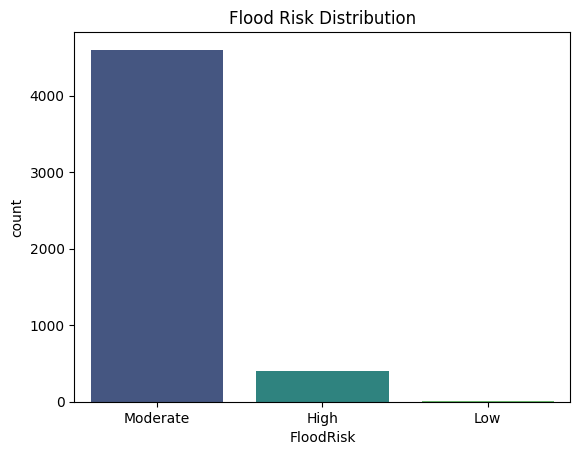

In [6]:
print(df["FloodRisk"].value_counts())

sns.countplot(
    x=df["FloodRisk"],
    palette="viridis"
)

plt.title("Flood Risk Distribution")
plt.show()

Step 6: Feature Selection
Python

In [7]:
X = df.drop(
    ["FloodProbability", "FloodRisk"],
    axis=1
)

y = df["FloodRisk"]

Step 7: Encode Target

In [8]:
encoder = LabelEncoder()

y = encoder.fit_transform(y)

print(encoder.classes_)

['High' 'Low' 'Moderate']


Output
["High", "Low", "Moderate"]

Step 8: Train-Test Split

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

Step 9: Build XGBoost Model
Python

In [10]:
from xgboost import XGBClassifier

model = XGBClassifier(
    objective='multi:softprob',
    num_class=3,
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='mlogloss'
)

model.fit(
    X_train,
    y_train
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=None, num_class=3, ...)

Step 10: Predictions

In [11]:
# Make sure you run Step 9 (cell 0WGyEXYF0pdG) first to train and define the 'model' variable.
y_pred = model.predict(X_test)

Step 11: Accuracy Score
Python

In [12]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Accuracy = ", accuracy)

Accuracy =  0.966


Step 12: Classification Report
Python

In [13]:
print(

    classification_report(
        y_test,
        y_pred,
        target_names=encoder.classes_
    )
)

              precision    recall  f1-score   support

        High       0.98      0.59      0.74        79
         Low       0.00      0.00      0.00         1
    Moderate       0.97      1.00      0.98       920

    accuracy                           0.97      1000
   macro avg       0.65      0.53      0.57      1000
weighted avg       0.97      0.97      0.96      1000



Step 13: Confusion Matrix
Python

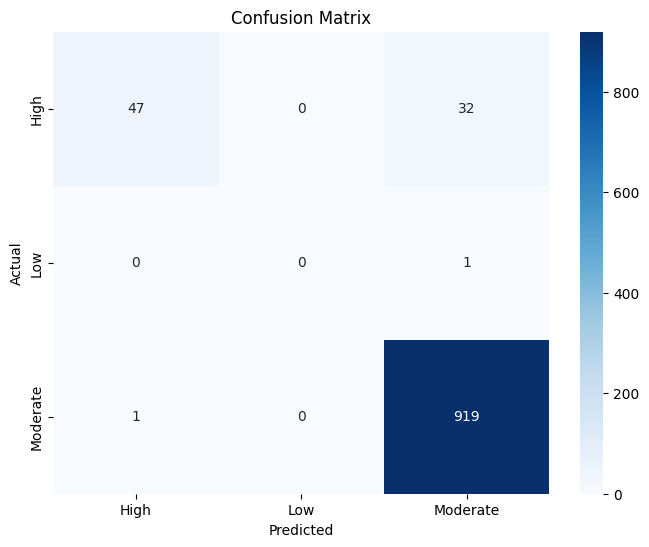

In [14]:
cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Confusion Matrix")

plt.show()

Step 14: Feature Importance

In [15]:
importance_df = pd.DataFrame({

    "Feature": X.columns,

    "Importance":
        model.feature_importances_

})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(
    importance_df.head(15)
)

                  Feature  Importance
6             DamsQuality    0.147372
4            Urbanization    0.122329
0        MonsoonIntensity    0.099963
1      TopographyDrainage    0.097097
10        DrainageSystems    0.087092
9           Encroachments    0.069800
7               Siltation    0.066325
5           ClimateChange    0.062641
8   AgriculturalPractices    0.057542
12        PopulationScore    0.052105
3           Deforestation    0.051477
11   CoastalVulnerability    0.049472
2         RiverManagement    0.036785


Step 15: Plot Feature Importance
Python

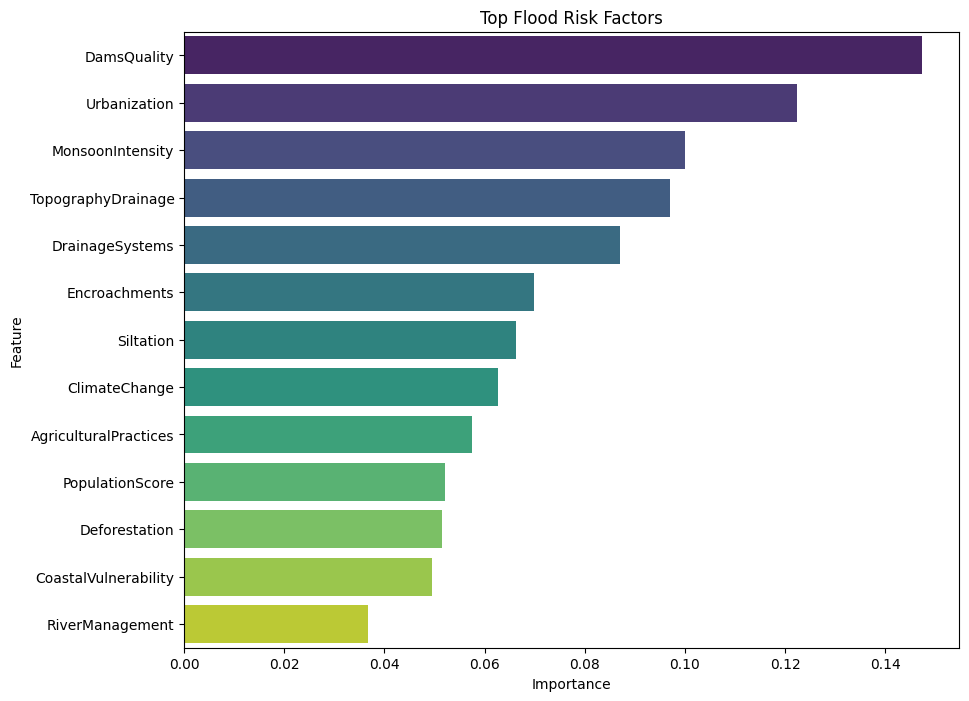

In [16]:
plt.figure(figsize=(10,8))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature",
    palette="viridis"
)

plt.title(
    "Top Flood Risk Factors"
)

plt.show()

Step 16: Save Trained Model
Python

In [17]:
joblib.dump(
    model,
    "FloodRiskClassifier.pkl"
)

joblib.dump(
    encoder,
    "LabelEncoder.pkl"
)

print("Model Saved")

Model Saved


Step 17: Future Community Prediction
Python

In [19]:
sample = pd.DataFrame({
    "MonsoonIntensity": [8],
    "TopographyDrainage": [6],
    "RiverManagement": [4],
    "Deforestation": [7],
    "Urbanization": [8],
    "ClimateChange": [8],
    "DamsQuality": [5],
    "Siltation": [6],
    "AgriculturalPractices": [5],
    "Encroachments": [7],
    "IneffectiveDisasterPreparedness": [7],
    "DrainageSystems": [4],
    "CoastalVulnerability": [5],
    "Landslides": [4],
    "Watersheds": [6],
    "DeterioratingInfrastructure": [7],
    "PopulationScore": [8],
    "WetlandLoss": [7],
    "InadequatePlanning": [8],
    "PoliticalFactors": [5]
})

# Filter the sample to only include the features the model was trained on and in the correct order
sample_filtered = sample[X.columns]

prediction = model.predict(sample_filtered)

risk = encoder.inverse_transform(prediction)

print("Predicted Flood Risk:", risk[0])

Predicted Flood Risk: Moderate


Repository Structure
Plain Text
Flood-Risk-Classifier/
│
├── data/
│ └── flood.csv
│
├── notebook/
│ └── Flood_Risk_Classifier.ipynb
│
├── models/
│ ├── FloodRiskClassifier.pkl
│ └── LabelEncoder.pkl
│
├── visuals/
│ ├── confusion_matrix.png
│ └── feature_importance.png
│
├── src/
│ └── train_model.py
│
├── requirements.txt
│
├── README.md
│
└── demo_video.mp4

[link text](https:// [link text](https://))7. requirements.txt
Plain Text
pandas
numpy
matplotlib
seaborn
scikit-learn
xgboost
joblib
tensorflow
keras

Submission Checklist

 Dataset (flood.csv)

 Google Colab Notebook

 XGBoost Model

 Confusion Matrix

 Feature Importance Plot

 Classification Report

 Accuracy Score

 Saved .pkl Model

 GitHub Repository

 README File

 2-3 Minute Demo Video

 Future Community Prediction Module

